# Classificação da Qualidade de Vinhos com Machine Learning

## Objetivo

O objetivo deste projeto é desenvolver modelos de Machine Learning capazes de classificar vinhos a partir de suas características físico-químicas.

A variável original `quality` será transformada em uma classificação binária:

- **0 - Baixa/Média qualidade:** nota menor que 7
- **1 - Alta qualidade:** nota maior ou igual a 7

O projeto será dividido nas seguintes etapas:

1. Compreensão e exploração dos dados
2. Preparação dos dados
3. Desenvolvimento dos modelos
4. Avaliação e comparação dos resultados
5. Interpretação dos resultados
6. Conclusão

In [ ]:
!pip install kagglehub[pandas-datasets]



In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import RobustScaler

## 1. Carregamento e Inspeção Inicial dos Dados

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

DATASET = "yasserh/wine-quality-dataset"

df_wine = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, DATASET, "WineQT.csv")

Using Colab cache for faster access to the 'wine-quality-dataset' dataset.


In [ ]:
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
df_wine.shape

(1143, 13)

In [ ]:
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
df_wine.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


### Análise inicial

O conjunto de dados utilizado possui **1.143 registros e 13 colunas**. As variáveis são numéricas, sendo 11 do tipo `float64` e 2 do tipo `int64`. A inspeção inicial também mostra 1.143 valores não nulos em todas as colunas, não indicando valores ausentes.

### 1.1 Verificação de Registros Duplicados

### Análise dos registros duplicados

Considerando todas as colunas, não foram encontradas linhas completamente duplicadas. A coluna `Id` possui 1.143 valores diferentes, indicando que funciona como um identificador único para cada registro.

Ao desconsiderar a coluna `Id`, foram encontrados **125 registros repetidos**. Como não há evidências de que esses registros representem erros, eles serão mantidos na análise. A coluna `Id`, por funcionar apenas como identificador, não será utilizada como variável de entrada nos modelos.

In [ ]:
df_wine.duplicated().sum()

np.int64(0)

In [ ]:
df_wine["Id"].nunique()

1143

In [ ]:
df_wine.drop(columns=["Id"]).duplicated().sum()

np.int64(125)

# 2. Análise Exploratória dos Dados (EDA)

## 2.1 Distribuição das Notas de Qualidade

In [ ]:
df_wine["quality"].value_counts().sort_index()

,count
quality,
3,6
4,33
5,483
6,462
7,143
8,16


-As notas não estão distribuídas igualmente. Há uma concentração muito grande nas notas 5 e 6.


In [ ]:
df_wine["quality"].value_counts(normalize=True).sort_index() * 100

,proportion
quality,
3,0.524934
4,2.887139
5,42.257218
6,40.419948
7,12.510936
8,1.399825


-A distribuição da variável quality está concentrada principalmente nas notas 5 e 6, que representam aproximadamente 82,7% dos registros. As notas extremas são pouco frequentes, especialmente as notas 3 e 8

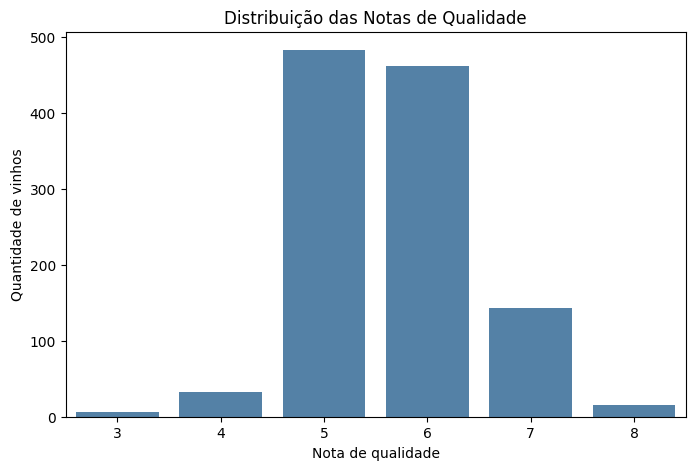

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
data=df_wine,
x="quality",
color="steelblue"
)

plt.title("Distribuição das Notas de Qualidade")
plt.xlabel("Nota de qualidade")
plt.ylabel("Quantidade de vinhos")


plt.show()

In [ ]:
df_wine["quality_bin"] = (df_wine["quality"] >= 7).astype(int)

In [ ]:
df_wine[["quality", "quality_bin"]].head(10)

,quality,quality_bin
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0


Verifica se quality é maior ou igual a 7. Se for, marca como 1; caso contrário, marque como 0

Verificando se as classes estão balanceadas

In [ ]:
df_wine["quality_bin"].value_counts()

,count
quality_bin,
0,984
1,159


In [ ]:
df_wine["quality_bin"].value_counts(normalize=True) * 100

,proportion
quality_bin,
0,86.089239
1,13.910761


As classes estão desbalanceadas: aproximadamente 86% dos vinhos pertencem à classe baixa/média qualidade, enquanto apenas 14% pertencem à classe alta qualidade.

Análise do balanceamento da variável alvo: Após a transformação da variável quality em uma variável binária, foram encontrados 984 registros (86,09%) classificados como baixa/média qualidade e 159 registros (13,91%) como alta qualidade. Portanto, observa-se um desbalanceamento relevante entre as classes, que deverá ser considerado nas etapas posteriores de treinamento e avaliação dos modelos.


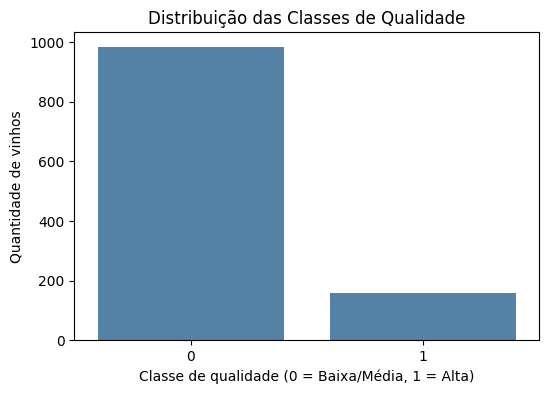

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
data=df_wine,
x="quality_bin",
color="steelblue"
)

plt.title("Distribuição das Classes de Qualidade")
plt.xlabel("Classe de qualidade (0 = Baixa/Média, 1 = Alta)")
plt.ylabel("Quantidade de vinhos")

plt.show()

Observa-se um desbalanceamento significativo entre as classes. A classe 0 (baixa/média qualidade) representa 86,09% dos registros, enquanto a classe 1 (alta qualidade) corresponde a apenas 13,91%. Esse desbalanceamento deverá ser considerado posteriormente durante o treinamento e a avaliação dos modelos.

In [ ]:
df_wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


Análise descritiva: Os dados mostram que algumas características dos vinhos variam bastante. Em variáveis como açúcar residual (residual sugar) e dióxido de enxofre (free sulfur dioxide e total sulfur dioxide), existem alguns valores bem maiores do que a maioria dos demais. Por isso, esses valores serão analisados com mais atenção nas próximas etapas. Neste momento, eles não serão excluídos, pois um valor muito alto ou muito baixo não significa necessariamente que o dado esteja errado.

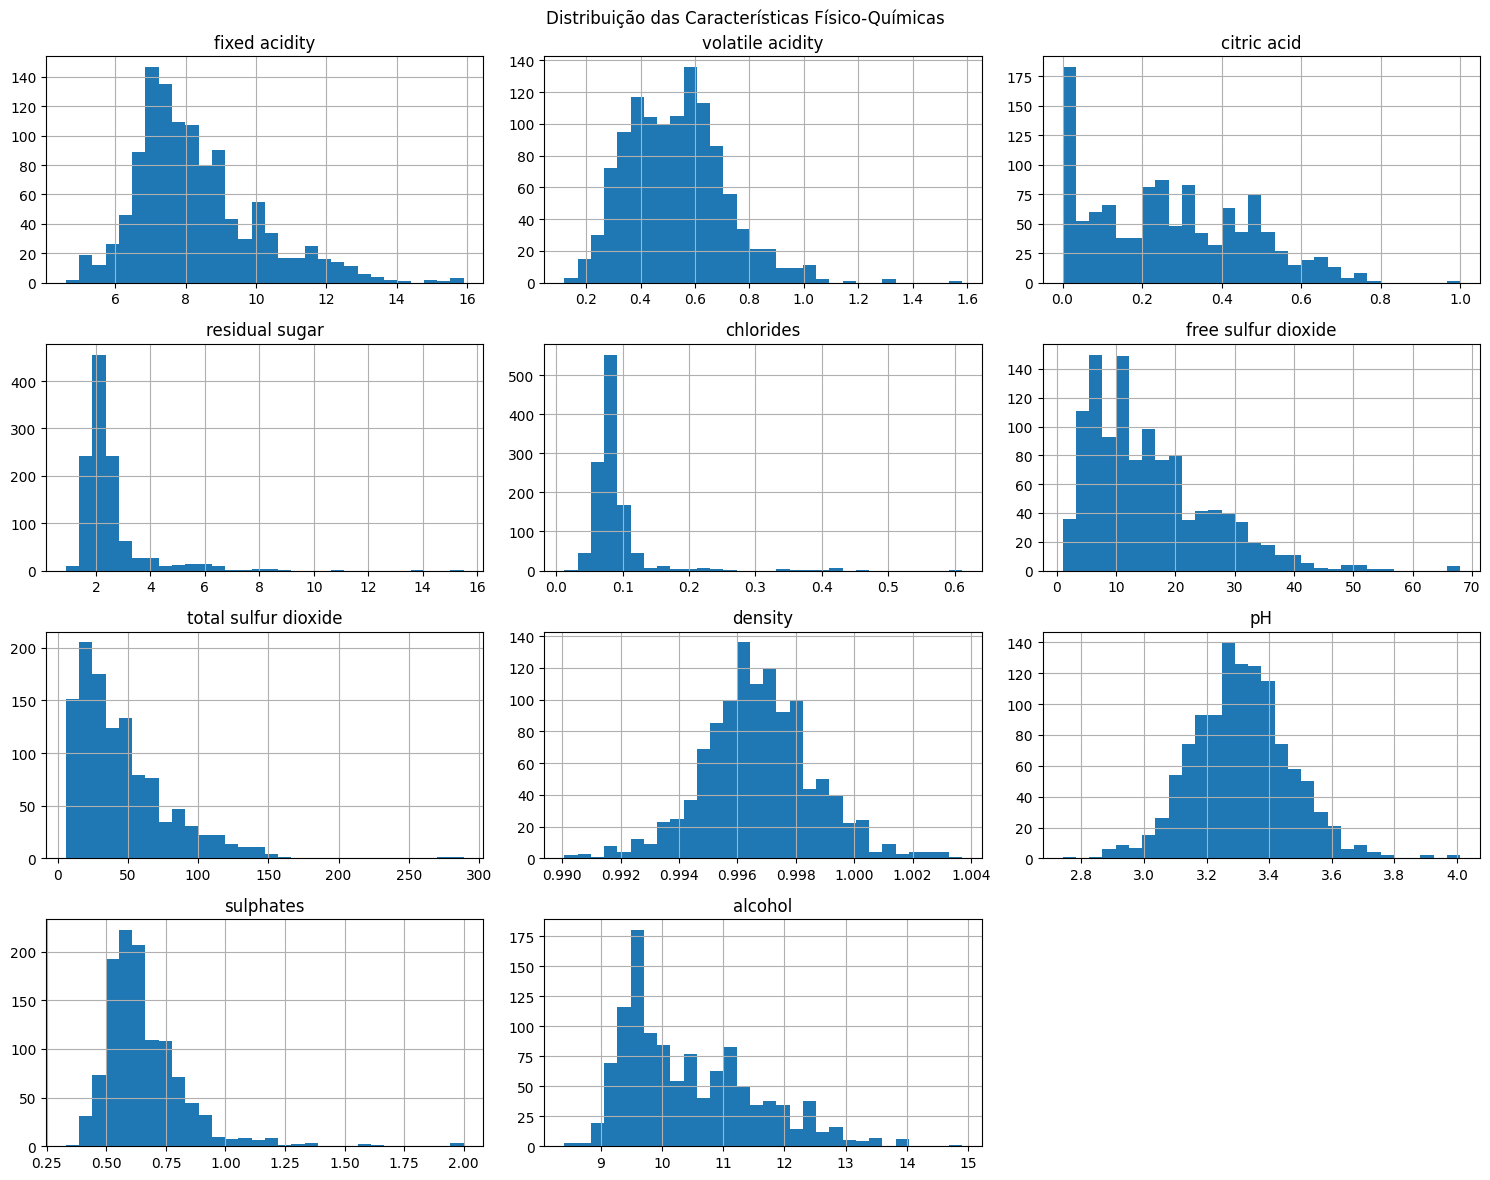

In [ ]:
features = [
"fixed acidity",
"volatile acidity",
"citric acid",
"residual sugar",
"chlorides",
"free sulfur dioxide",
"total sulfur dioxide",
"density",
"pH",
"sulphates",
"alcohol"
]

df_wine[features].hist(
figsize=(15, 12),
bins=30
)

plt.suptitle("Distribuição das Características Físico-Químicas")
plt.tight_layout()
plt.show()

Análise das distribuições: Os gráficos mostram que as características dos vinhos possuem comportamentos diferentes. Algumas apresentam valores mais concentrados, enquanto outras possuem poucos registros com valores bem maiores do que a maioria. Isso acontece, por exemplo, com açúcar residual, dióxido de enxofre, cloretos e sulfatos. Esses valores precisam ser investigados com mais atenção antes de decidir se algum tratamento será necessário.

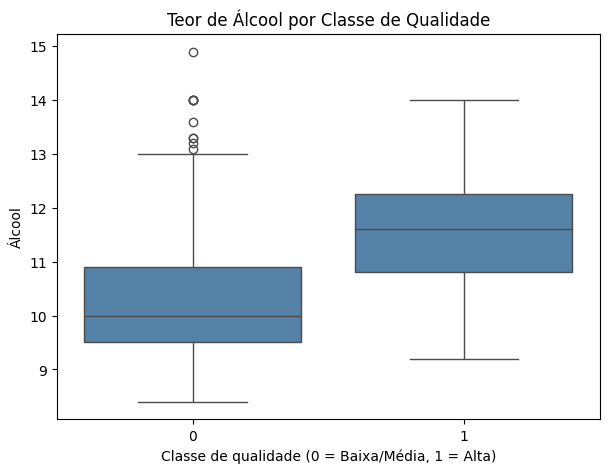

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
data=df_wine,
x="quality_bin",
y="alcohol",
color="steelblue"
)

plt.title("Teor de Álcool por Classe de Qualidade")
plt.xlabel("Classe de qualidade (0 = Baixa/Média, 1 = Alta)")
plt.ylabel("Álcool")

plt.show()

Álcool e qualidade: O gráfico mostra que os vinhos classificados como de alta qualidade tendem a apresentar maior teor de álcool. A classe de alta qualidade apresenta valores de álcool geralmente superiores aos encontrados na classe de baixa/média qualidade. Porém, existem exceções, portanto o teor de álcool sozinho não é suficiente para determinar a qualidade do vinho.

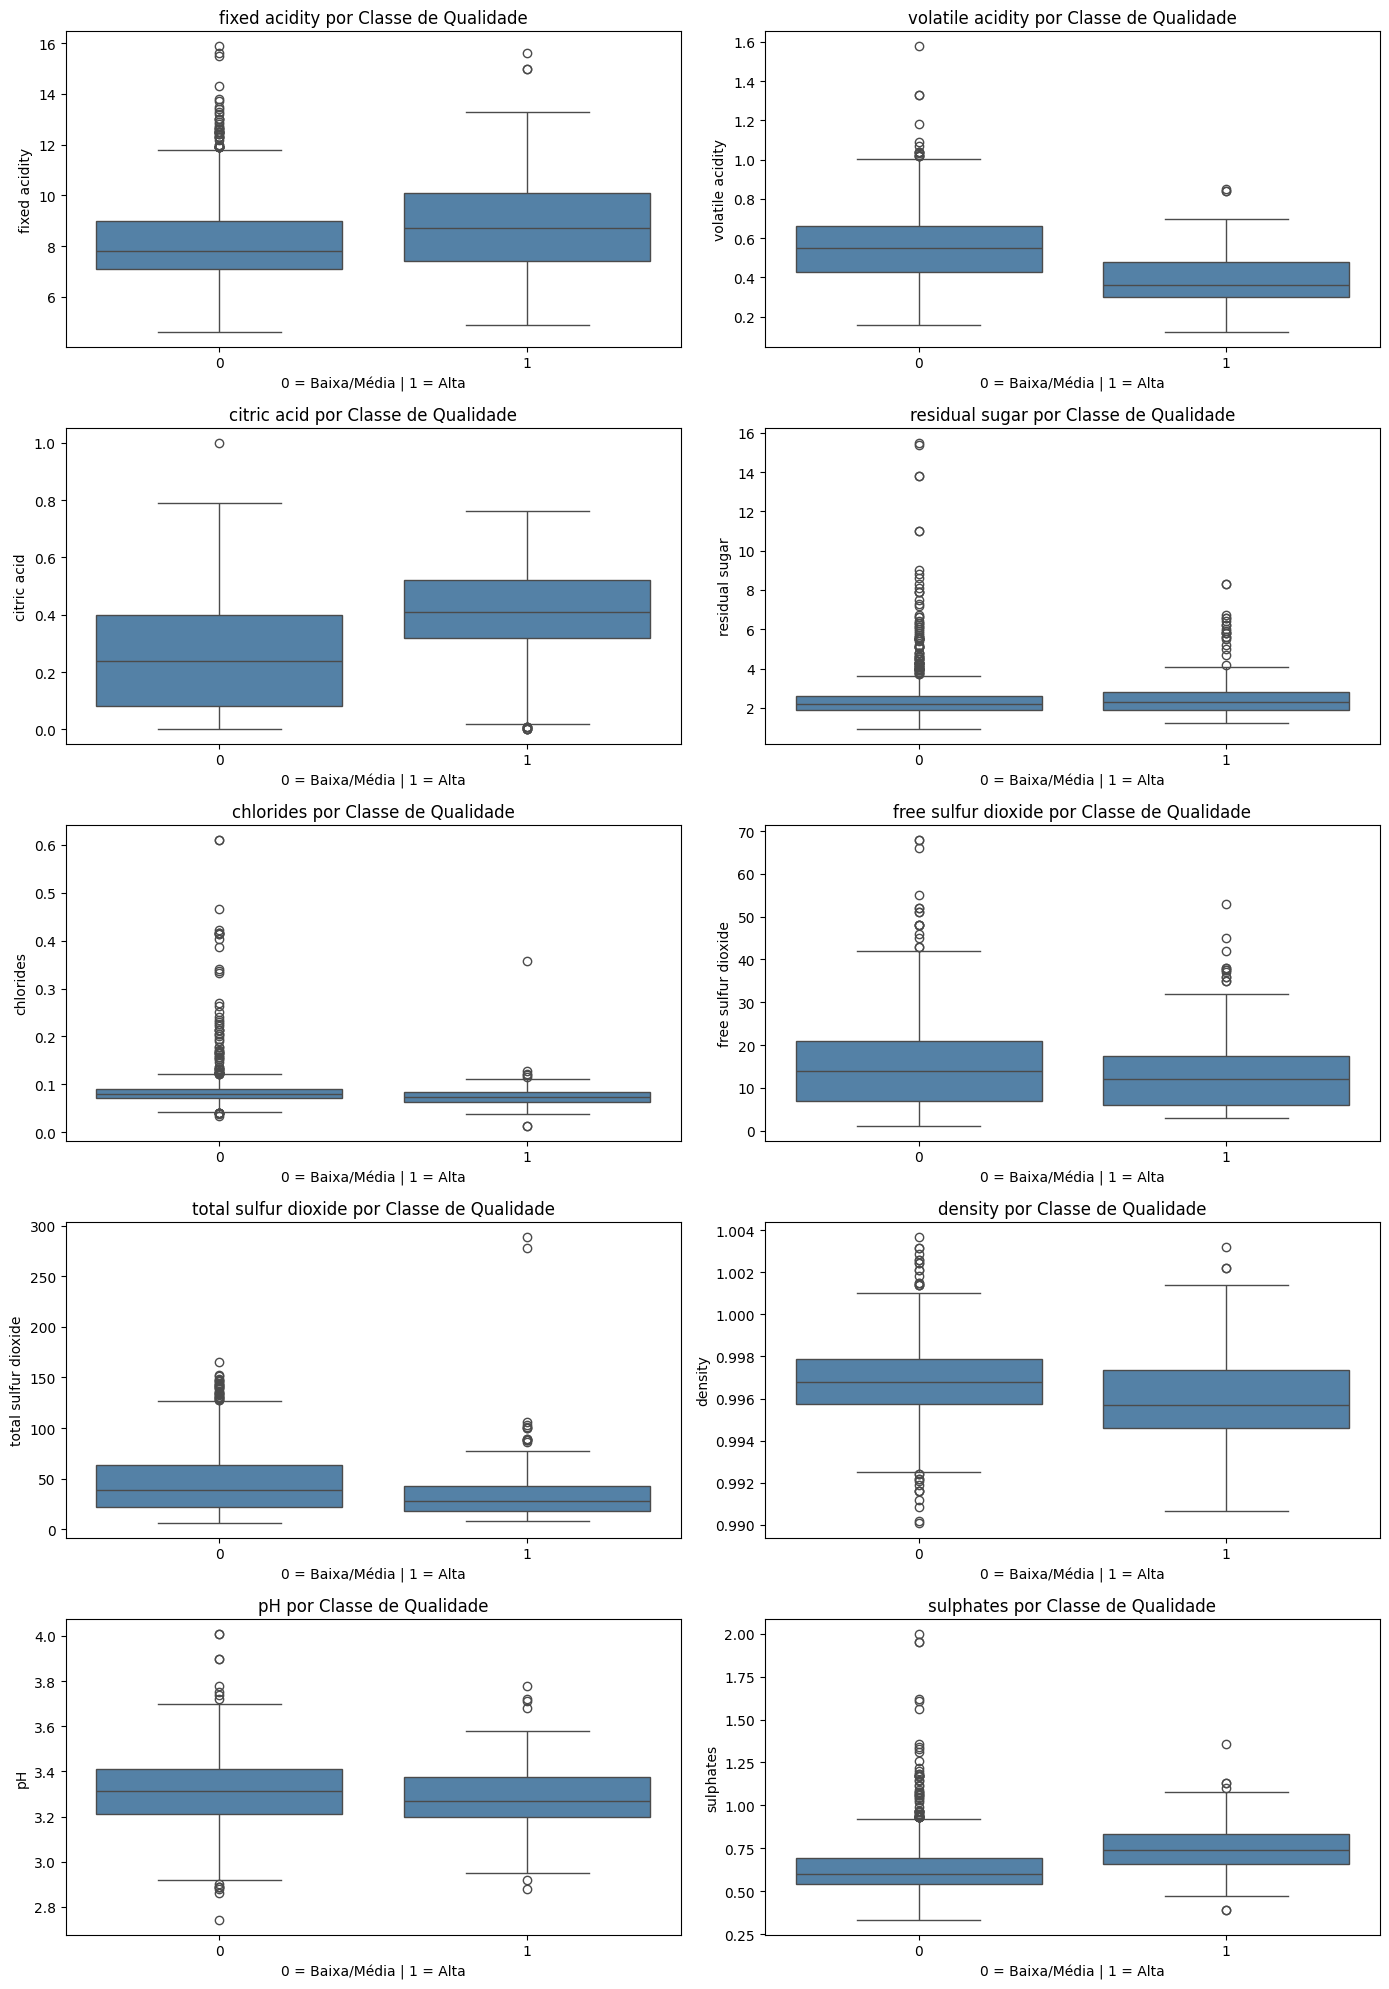

In [ ]:
features_sem_alcohol = [
  "fixed acidity",
  "volatile acidity",
  "citric acid",
  "residual sugar",
  "chlorides",
  "free sulfur dioxide",
  "total sulfur dioxide",
  "density",
  "pH",
  "sulphates"
]

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

axes = axes.flatten()

for i, feature in enumerate(features_sem_alcohol):
  sns.boxplot(
    data=df_wine,
   x="quality_bin",
   y=feature,
    ax=axes[i],
   color="steelblue"
  )

  axes[i].set_title(f"{feature} por Classe de Qualidade")
  axes[i].set_xlabel("0 = Baixa/Média | 1 = Alta")
  axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

Comparação das características com a qualidade: A comparação entre os dois grupos mostra que algumas características apresentam diferenças mais visíveis. Os vinhos classificados como de alta qualidade tendem a apresentar maior teor de álcool, maior quantidade de sulfatos e ácido cítrico e menor acidez volátil e densidade. Outras características apresentam distribuições mais parecidas entre os dois grupos. Essas diferenças são apenas indícios e serão investigadas em conjunto com outras análises antes da construção dos modelos.

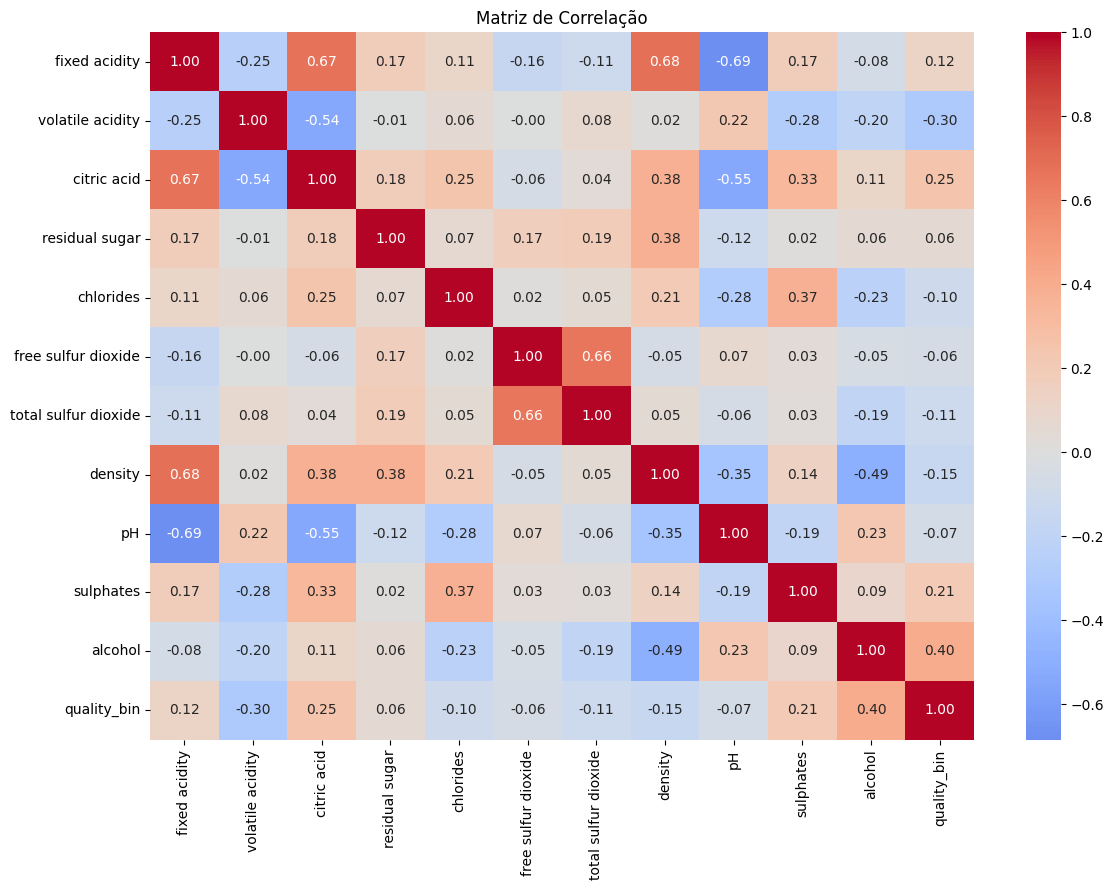

In [ ]:
colunas_correlacao = [
  "fixed acidity",
  "volatile acidity",
  "citric acid",
  "residual sugar",
  "chlorides",
  "free sulfur dioxide",
  "total sulfur dioxide",
  "density",
  "pH",
  "sulphates",
  "alcohol",
  "quality_bin"
]

correlacao = df_wine[colunas_correlacao].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
  correlacao,
  annot=True,
  fmt=".2f",
  cmap="coolwarm",
  center=0
)
plt.title("Matriz de Correlação")
plt.tight_layout()
plt.show()

Análise de correlação: A matriz de correlação mostra que algumas características apresentam maior relação com a classificação de qualidade. O teor de álcool apresentou a maior correlação positiva com a alta qualidade (0,40). O ácido cítrico (0,25) e os sulfatos (0,21) também apresentaram relações positivas. Já a acidez volátil apresentou uma correlação negativa (-0,30), indicando que valores menores dessa característica tendem a estar associados aos vinhos classificados como de alta qualidade. As demais características apresentaram relações mais fracas com a classificação.

Relação entre as características: Além da relação com a qualidade, algumas características físico-químicas também apresentam relação entre si. Por exemplo, a acidez fixa possui relação com o pH, a densidade e o ácido cítrico. Também existe uma relação entre o dióxido de enxofre livre e o dióxido de enxofre total. Isso mostra que algumas características dos vinhos podem variar de forma relacionada.

Uma correlação alta entre duas características não significa que uma seja a causa da outra. A correlação apenas indica que existe uma relação entre os valores observados no conjunto de dados.

In [ ]:
outliers = {}

for coluna in features:
  Q1 = df_wine[coluna].quantile(0.25)
  Q3 = df_wine[coluna].quantile(0.75)

  IQR = Q3 - Q1

  limite_inferior = Q1 - 1.5 * IQR
  limite_superior = Q3 + 1.5 * IQR

  quantidade = df_wine[
    (df_wine[coluna] < limite_inferior) |
    (df_wine[coluna] > limite_superior)
  ].shape[0]

  outliers[coluna] = quantidade

outliers

{'fixed acidity': 44,
 'volatile acidity': 14,
 'citric acid': 1,
 'residual sugar': 110,
 'chlorides': 77,
 'free sulfur dioxide': 18,
 'total sulfur dioxide': 40,
 'density': 36,
 'pH': 20,
 'sulphates': 43,
 'alcohol': 12}

Análise de valores extremos: Foram identificados possíveis valores extremos em várias características do conjunto de dados. O açúcar residual (residual sugar) apresentou a maior quantidade de ocorrências, seguido por cloretos (chlorides). Esses valores não serão removidos automaticamente, pois podem representar características reais dos vinhos e não necessariamente erros nos dados.

In [ ]:
X = df_wine.drop(columns=["Id", "quality", "quality_bin"])

y = df_wine["quality_bin"]

In [ ]:
print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

X.head()

Formato de X: (1143, 11)
Formato de y: (1143,)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


Desbalanceamento das classes: Como a classe 0 representa aproximadamente 86% dos registros e a classe 1 cerca de 14%, o conjunto de dados apresenta desbalanceamento. A divisão entre treino e teste será realizada de forma estratificada para manter aproximadamente essa proporção nos dois conjuntos. Possíveis estratégias para lidar com o desbalanceamento serão aplicadas apenas aos dados de treinamento, evitando alterar a distribuição original do conjunto de teste.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  test_size=0.20,
  random_state=42,
  stratify=y
)

print("X treino:", X_train.shape)
print("X teste:", X_test.shape)
print("y treino:", y_train.shape)
print("y teste:", y_test.shape)

X treino: (914, 11)
X teste: (229, 11)
y treino: (914,)
y teste: (229,)


Verificando se as classes ficaram com proporções semelhantes

In [ ]:
print("Distribuição no treino:")
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribuição no teste:")
print(y_test.value_counts(normalize=True) * 100)

Distribuição no treino:
quality_bin
0    86.105033
1    13.894967
Name: proportion, dtype: float64

Distribuição no teste:
quality_bin
0    86.026201
1    13.973799
Name: proportion, dtype: float64


Verificação da divisão: A divisão estratificada manteve praticamente a mesma proporção das classes nos conjuntos de treino e teste. A classe de baixa/média qualidade representa aproximadamente 86% dos registros, enquanto a classe de alta qualidade representa cerca de 14% em ambos os conjuntos.

padronizar as variáveis, porque características como density, alcohol e total sulfur dioxide estão em escalas bem diferentes.

density → perto de 1
total sulfur dioxide → pode passar de 100

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

O scaler.fit_transform(X_train) --> aprende usando somente os dados de treino.
não deixamos informações do conjunto de teste influenciarem a preparação do modelo.

scaler.transform(X_test) --> não deixa informações do conjunto de teste influenciar a preparação do modelo.

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo_baseline = LogisticRegression(
random_state=42,
max_iter=1000
)

modelo_baseline.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

o modelo está aprendendo a relação entre:

11 características físico-químicas
↓
Regressão Logística
↓
0 ou 1

In [ ]:
y_pred = modelo_baseline.predict(X_test_scaled)

Agora o modelo recebe os 229 vinhos que ficaram separados para teste e gera uma previsão 0 ou 1 para cada um.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Matriz de Confusão:
[[187  10]
 [ 21  11]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.90      0.95      0.92       197
           1       0.52      0.34      0.42        32

    accuracy                           0.86       229
   macro avg       0.71      0.65      0.67       229
weighted avg       0.85      0.86      0.85       229



Resultado do modelo baseline: A Regressão Logística apresentou acurácia de 86%. No entanto, ao analisar as classes separadamente, observa-se uma diferença importante no desempenho. O modelo identificou corretamente 95% dos casos da classe 0, mas apenas 34% dos casos da classe 1. Dos 32 vinhos de alta qualidade presentes no conjunto de teste, apenas 11 foram identificados corretamente. Portanto, a acurácia isoladamente pode transmitir uma impressão melhor do desempenho do modelo do que realmente ocorre para a classe minoritária.

O resultado indica a necessidade de testar estratégias para lidar com o desbalanceamento das classes e verificar se é possível melhorar a identificação dos vinhos de alta qualidade sem comprometer excessivamente o desempenho geral.

In [ ]:
LogisticRegression(
  class_weight="balanced",
  random_state=42,
  max_iter=1000
)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

Regressão Logística com balanceamento: Como existem muito mais vinhos da classe 0 do que da classe 1, foi criado um novo modelo considerando esse desequilíbrio. O parâmetro class_weight="balanced" faz o modelo dar mais atenção à classe que possui menos exemplos. O objetivo é verificar se conseguimos identificar melhor os vinhos de alta qualidade.

In [ ]:
modelo_balanceado = LogisticRegression(
  class_weight="balanced",
  random_state=42,
  max_iter=1000
)

modelo_balanceado.fit(X_train_scaled, y_train)

y_pred_balanceado = modelo_balanceado.predict(X_test_scaled)

In [ ]:
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_balanceado))

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_balanceado))

Matriz de Confusão:
[[161  36]
 [ 10  22]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       197
           1       0.38      0.69      0.49        32

    accuracy                           0.80       229
   macro avg       0.66      0.75      0.68       229
weighted avg       0.86      0.80      0.82       229



Resultado do modelo balanceado: O modelo passou a identificar melhor os vinhos de alta qualidade. Dos 32 vinhos de alta qualidade presentes no conjunto de teste, 22 foram identificados corretamente, enquanto 10 não foram identificados. O recall da classe 1 aumentou de 34% para 69% em comparação com o primeiro modelo.

Por outro lado, o modelo também passou a classificar mais vinhos de baixa/média qualidade como se fossem de alta qualidade. Por isso, a acurácia geral caiu de 86% para 80%. Isso mostra que o balanceamento melhorou a identificação da classe menos frequente, mas também aumentou os erros na classe mais comum.

Conclusão: O modelo balanceado foi melhor para encontrar vinhos de alta qualidade, que é justamente a classe com menos exemplos no conjunto de dados. Por esse motivo, mesmo tendo uma acurácia geral menor, esse modelo apresenta uma melhora importante na identificação da classe 1.

Random Forest sem balanceamento

Modelo Random Forest: Como segundo algoritmo, será utilizado o Random Forest para comparar seu desempenho com a Regressão Logística. Primeiro, o modelo será treinado sem nenhum ajuste para o desbalanceamento das classes. Depois, será avaliada sua capacidade de identificar os vinhos de alta qualidade.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
  n_estimators=100,
  random_state=42
)

modelo_rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

previsões

In [ ]:
y_pred_rf = modelo_rf.predict(X_test)

Avaliar o Randon forest

In [ ]:
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_rf))

Matriz de Confusão:
[[192   5]
 [ 13  19]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.97      0.96       197
           1       0.79      0.59      0.68        32

    accuracy                           0.92       229
   macro avg       0.86      0.78      0.82       229
weighted avg       0.92      0.92      0.92       229



Resultado do Random Forest: O modelo apresentou acurácia de 92%. Entre os 32 vinhos de alta qualidade presentes no teste, 19 foram identificados corretamente e 13 foram classificados incorretamente como baixa/média qualidade. O modelo apresentou recall de 59% e precision de 79% para a classe de alta qualidade.

Comparando com a Regressão Logística inicial, o Random Forest apresentou um resultado mais equilibrado, conseguindo identificar uma quantidade maior de vinhos de alta qualidade e, ao mesmo tempo, mantendo poucos erros ao classificar vinhos de baixa/média qualidade como alta qualidade.

Random Forest é o melhor até agora em acurácia, precision e F1 da classe 1.
Regressão Logística balanceada ainda possui o maior recall da classe 1, 69%, ou seja, encontrou mais vinhos de alta qualidade.
Portanto, ainda não precisamos declarar um vencedor absoluto. A escolha depende também de qual tipo de erro consideramos mais importante.

Random Forest com balanceamento: Como existem menos vinhos de alta qualidade no conjunto de treinamento, será testada uma segunda versão do Random Forest considerando o desbalanceamento das classes. O objetivo é verificar se o modelo consegue identificar mais vinhos da classe 1.

In [ ]:
modelo_rf_balanceado = RandomForestClassifier(
  n_estimators=100,
  class_weight="balanced",
  random_state=42
)

modelo_rf_balanceado.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

previsões

In [ ]:
y_pred_rf_balanceado = modelo_rf_balanceado.predict(X_test)

Avaliar

In [ ]:
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_rf_balanceado))

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_rf_balanceado))

Matriz de Confusão:
[[193   4]
 [ 16  16]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95       197
           1       0.80      0.50      0.62        32

    accuracy                           0.91       229
   macro avg       0.86      0.74      0.78       229
weighted avg       0.91      0.91      0.90       229



Resultado do Random Forest balanceado: O modelo apresentou acurácia de 91%. Dos 32 vinhos de alta qualidade presentes no conjunto de teste, 16 foram identificados corretamente e 16 não foram identificados. O recall da classe 1 foi de 50%, enquanto a precision foi de 80%.

Ao comparar com o Random Forest sem balanceamento, o uso do balanceamento não trouxe melhora neste experimento. O Random Forest original apresentou recall de 59% e F1-score de 68% para a classe de alta qualidade, enquanto a versão balanceada apresentou recall de 50% e F1-score de 62%.

Até o momento, o Random Forest sem balanceamento apresentou o melhor equilíbrio entre identificar corretamente os vinhos de alta qualidade e evitar classificações incorretas.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
  n_splits=5,
  shuffle=True,
  random_state=42
)

metricas = {
  "accuracy": "accuracy",
  "precision": "precision",
  "recall": "recall",
  "f1": "f1",
  "roc_auc": "roc_auc"
}

resultado_cv_rf = cross_validate(
  modelo_rf,
  X_train,
  y_train,
  cv=cv,
  scoring=metricas
)

In [ ]:
print("Resultados médios da validação cruzada:")

print("Acurácia:", resultado_cv_rf["test_accuracy"].mean())
print("Precision:", resultado_cv_rf["test_precision"].mean())
print("Recall:", resultado_cv_rf["test_recall"].mean())
print("F1-score:", resultado_cv_rf["test_f1"].mean())
print("ROC-AUC:", resultado_cv_rf["test_roc_auc"].mean())

Resultados médios da validação cruzada:
Acurácia: 0.9048399687743951
Precision: 0.748538961038961
Recall: 0.48923076923076925
F1-score: 0.5883386463043963
ROC-AUC: 0.9161416902858491


A acurácia de 90,5% mostra que, no geral, o modelo acertou bastante.

A precision de 74,9% significa que, quando o modelo indica que um vinho é de alta qualidade, ele costuma acertar com boa frequência.

Já o recall de 48,9% merece atenção: em média, o modelo encontrou aproximadamente metade dos vinhos de alta qualidade nas diferentes divisões da validação.

O F1-score de 58,8% reflete esse equilíbrio entre precision e recall.

E o ROC-AUC de 91,6% indica uma boa capacidade do modelo de distinguir as duas classes ao considerar diferentes limiares de decisão.

Validação cruzada: Para verificar se o resultado do Random Forest se mantém quando os dados de treinamento são divididos de maneiras diferentes, foi realizada uma validação cruzada com 5 divisões. O modelo apresentou, em média, 90,5% de acurácia e ROC-AUC de 91,6%. Porém, o recall médio da classe de alta qualidade foi de 48,9%, mostrando que o modelo ainda apresenta dificuldade para identificar todos os vinhos dessa classe.

Conclusão: O Random Forest apresenta um bom desempenho geral e uma boa capacidade de diferenciar as classes. Porém, os resultados da validação cruzada mostram que ainda existe espaço para melhorar a identificação dos vinhos de alta qualidade.

In [ ]:
y_prob_log = modelo_baseline.predict_proba(X_test_scaled)[:, 1]
y_prob_log_bal = modelo_balanceado.predict_proba(X_test_scaled)[:, 1]

y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]
y_prob_rf_bal = modelo_rf_balanceado.predict_proba(X_test)[:, 1]

Probabilidades dos modelos: Para construir a Curva ROC, foram calculadas as probabilidades de cada vinho pertencer à classe de alta qualidade. Diferente da previsão final, que retorna apenas 0 ou 1, essa etapa permite analisar o nível de confiança do modelo para diferentes limites de classificação.

Curva ROC: A Curva ROC será utilizada para comparar a capacidade dos modelos de diferenciar os vinhos de baixa/média qualidade dos vinhos de alta qualidade. O valor ROC-AUC resume esse desempenho, permitindo complementar a análise feita anteriormente com acurácia, precision, recall e F1-score.

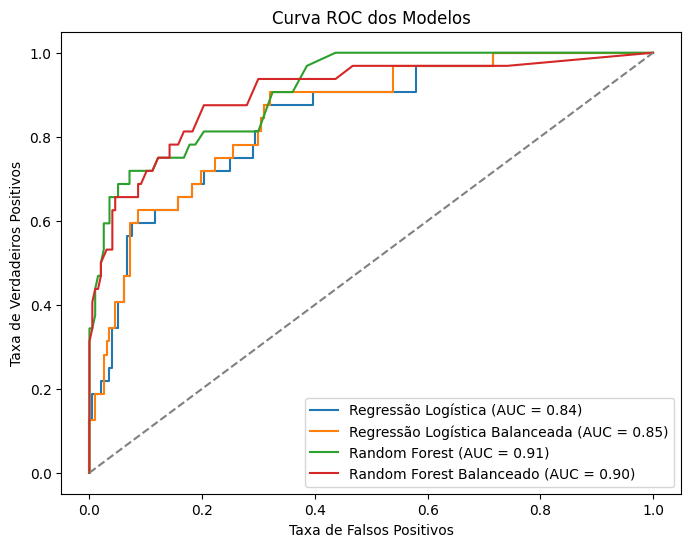

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_log_bal, tpr_log_bal, _ = roc_curve(y_test, y_prob_log_bal)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_rf_bal, tpr_rf_bal, _ = roc_curve(y_test, y_prob_rf_bal)

auc_log = roc_auc_score(y_test, y_prob_log)
auc_log_bal = roc_auc_score(y_test, y_prob_log_bal)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_rf_bal = roc_auc_score(y_test, y_prob_rf_bal)

plt.figure(figsize=(8, 6))

plt.plot(fpr_log, tpr_log, label=f"Regressão Logística (AUC = {auc_log:.2f})")
plt.plot(fpr_log_bal, tpr_log_bal, label=f"Regressão Logística Balanceada (AUC = {auc_log_bal:.2f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.2f})")
plt.plot(fpr_rf_bal, tpr_rf_bal, label=f"Random Forest Balanceado (AUC = {auc_rf_bal:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("Taxa de Falsos Positivos")
plt.ylabel("Taxa de Verdadeiros Positivos")
plt.title("Curva ROC dos Modelos")
plt.legend()

plt.show()

Quanto mais o valor do AUC se aproxima de 1, melhor o modelo consegue diferenciar os vinhos das duas classes.

A linha pontilhada representa uma referência de classificação sem poder de separação. As curvas dos quatro modelos estão acima dela, e as duas curvas do Random Forest apresentam os maiores valores de AUC.

Análise da Curva ROC: A comparação mostrou que o Random Forest sem balanceamento apresentou o maior ROC-AUC, com valor de 0,91. O Random Forest balanceado ficou próximo, com 0,90. Já as duas versões da Regressão Logística apresentaram valores de 0,84 e 0,85. Esses resultados indicam que o Random Forest apresentou melhor capacidade de diferenciar vinhos de alta qualidade dos vinhos de baixa/média qualidade.

Até agora, o Random Forest sem balanceamento apresentou o melhor equilíbrio geral:

Acurácia: 92%
Precision da classe 1: 79%
Recall da classe 1: 59%
F1 da classe 1: 68%
ROC-AUC: 0,91

A Regressão Logística balanceada continua tendo uma vantagem específica: apresentou recall de 69%, identificando mais vinhos de alta qualidade, mas com mais falsos positivos.

Conclusão: Considerando o conjunto das métricas avaliadas, o Random Forest sem balanceamento apresentou o melhor equilíbrio geral entre desempenho, identificação da classe de alta qualidade e capacidade de separação das classes. Entretanto, caso o objetivo principal fosse encontrar a maior quantidade possível de vinhos de alta qualidade, o maior recall obtido pela Regressão Logística balanceada também deveria ser considerado.

In [ ]:
import pandas as pd

importancias = pd.DataFrame({
  "Característica": X_train.columns,
  "Importância": modelo_rf.feature_importances_
})

importancias = importancias.sort_values(
  by="Importância",
  ascending=False
)

importancias

,Característica,Importância
10,alcohol,0.167148
9,sulphates,0.120996
1,volatile acidity,0.115583
2,citric acid,0.107727
7,density,0.096828
0,fixed acidity,0.075293
6,total sulfur dioxide,0.072271
8,pH,0.068435
3,residual sugar,0.062453
4,chlorides,0.059084


modelo_rf.feature_importances_ --->Esse atributo fornece uma medida da importância de cada característica para as decisões feitas pelas árvores do modelo.

Depois organizamos os valores:
Mais importante
↓
↓
Menos importante


As características que apareceram relacionadas à qualidade durante a EDA também aparecem entre as mais importantes para o Random Forest?


EDA → identificou relações nos dados → Random Forest → utilizou essas características nas previsões.


Importância das características: Após avaliar os modelos, foi analisada a importância das características utilizadas pelo Random Forest. O objetivo é entender quais informações físico-químicas tiveram maior participação nas decisões do modelo e comparar esses resultados com os padrões observados anteriormente na análise exploratória.

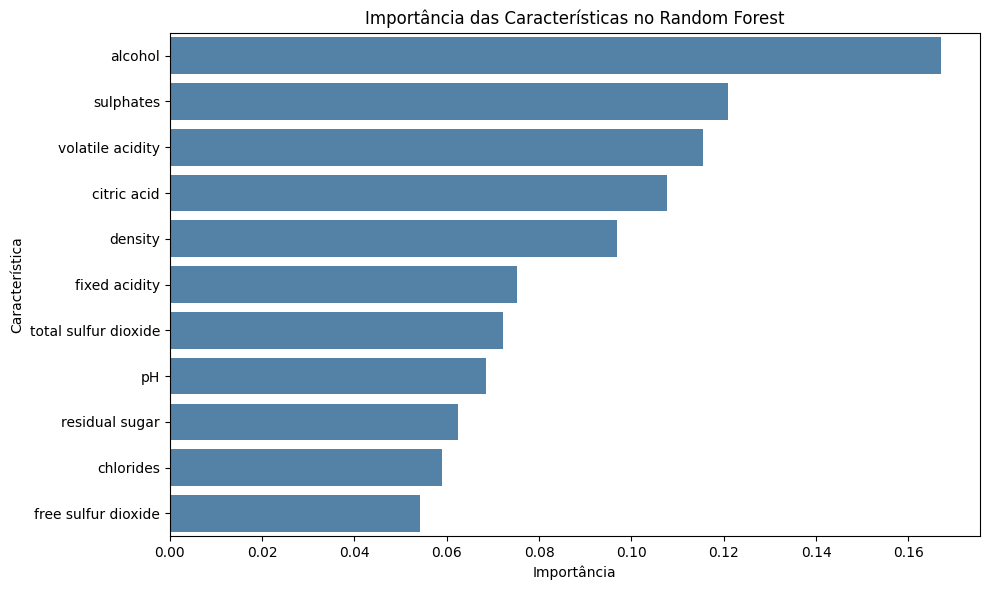

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
data=importancias,
  x="Importância",
  y="Característica",
  color="steelblue"
)

plt.title("Importância das Características no Random Forest")
plt.xlabel("Importância")
plt.ylabel("Característica")

plt.tight_layout()
plt.show()

In [ ]:
# Definindo X (variáveis físico-químicas sem 'Id' e 'quality') e y (alvo binário)
X = df_wine[features]
y = df_wine["quality_bin"]

# Divisão em treino e teste mantendo a proporção das classes (stratify=y)
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Padronização com RobustScaler (ideal para lidar com outliers)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Instanciando o modelo Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE
)

# Validação cruzada estratificada (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1_gb = cross_val_score(gb_model, X_train_scaled, y_train, cv=cv, scoring="f1")
cv_auc_gb = cross_val_score(
    gb_model, X_train_scaled, y_train, cv=cv, scoring="roc_auc"
)

print(
    f"Gradient Boosting - F1-Score (CV): {cv_f1_gb.mean():.4f} ± {cv_f1_gb.std():.4f}"
)
print(
    f"Gradient Boosting - ROC-AUC (CV):  {cv_auc_gb.mean():.4f} ± {cv_auc_gb.std():.4f}"
)

# Treinamento final nos dados de treino
gb_model.fit(X_train_scaled, y_train)

# Previsões nos dados de teste
y_pred_gb = gb_model.predict(X_test_scaled)
y_proba_gb = gb_model.predict_proba(X_test_scaled)[:, 1]

Gradient Boosting - F1-Score (CV): 0.5408 ± 0.0922
Gradient Boosting - ROC-AUC (CV):  0.9059 ± 0.0221


=== Desempenho no Teste: Gradient Boosting ===
Acurácia:  0.8996
Precisão:  0.6667
Recall:    0.5625
F1-Score:  0.6102
ROC-AUC:   0.8783

Relatório de Classificação:
                 precision    recall  f1-score   support

Baixa/Média (0)       0.93      0.95      0.94       197
       Alta (1)       0.67      0.56      0.61        32

       accuracy                           0.90       229
      macro avg       0.80      0.76      0.78       229
   weighted avg       0.89      0.90      0.90       229



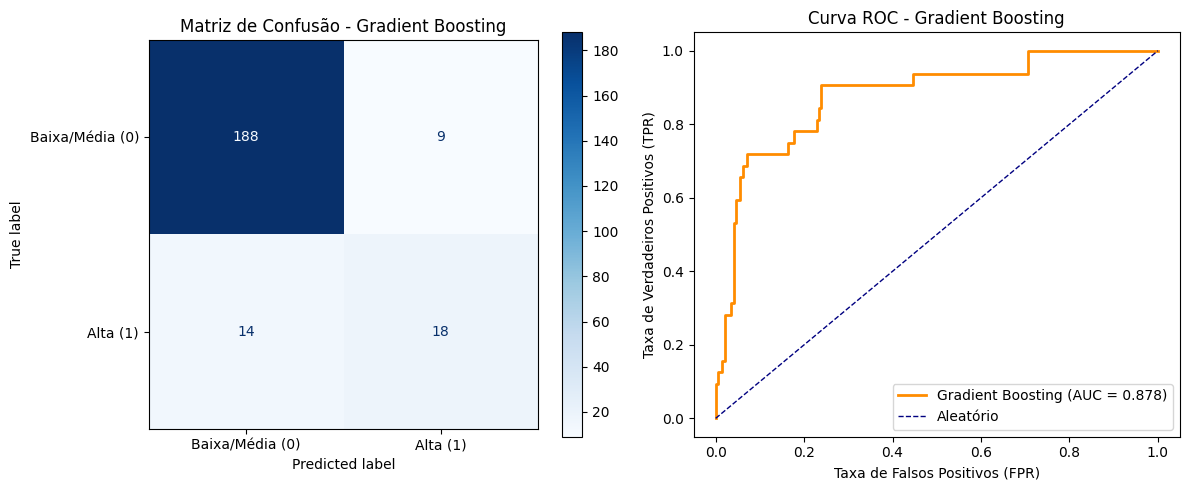

In [ ]:
# Cálculo das métricas no conjunto de teste
acc_gb = accuracy_score(y_test, y_pred_gb)
prec_gb = precision_score(y_test, y_pred_gb)
rec_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
auc_gb = roc_auc_score(y_test, y_proba_gb)

print("=== Desempenho no Teste: Gradient Boosting ===")
print(f"Acurácia:  {acc_gb:.4f}")
print(f"Precisão:  {prec_gb:.4f}")
print(f"Recall:    {rec_gb:.4f}")
print(f"F1-Score:  {f1_gb:.4f}")
print(f"ROC-AUC:   {auc_gb:.4f}\n")
print("Relatório de Classificação:")
print(
    classification_report(
        y_test, y_pred_gb, target_names=["Baixa/Média (0)", "Alta (1)"]
    )
)

# Plotando Matriz de Confusão e Curva ROC lado a lado
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_gb,
    display_labels=["Baixa/Média (0)", "Alta (1)"],
    cmap="Blues",
    ax=ax[0],
)
ax[0].set_title("Matriz de Confusão - Gradient Boosting")
ax[0].grid(False)

# Curva ROC
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_proba_gb)
ax[1].plot(
    fpr_gb,
    tpr_gb,
    color="darkorange",
    lw=2,
    label=f"Gradient Boosting (AUC = {auc_gb:.3f})",
)
ax[1].plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Aleatório")
ax[1].set_title("Curva ROC - Gradient Boosting")
ax[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
ax[1].set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

A ordem de importância encontrada pelo Random Forest foi aproximadamente:

1 alcohol
2 sulphates
3 volatile acidity
4 citric acid
5 density
6 fixed acidity
7 total sulfur dioxide
8 pH
9 residual sugar
10 chlorides
11 free sulfur dioxide

Comparando EDA x Random Forest

Na matriz de correlação, tínhamos observado:

alcohol: +0,40
volatile acidity: -0,30
citric acid: +0,25
sulphates: +0,21
density: -0,15

EDA → encontramos sinais de associação com a qualidade
 ↓
 Modelagem → o Random Forest também utilizou bastante essas características
 ↓
 Interpretação → especialmente álcool, sulfatos, acidez volátil, ácido cítrico e densidade merecem destaque

Importância das características: A análise do Random Forest mostrou que o teor de álcool (alcohol) foi a característica com maior importância nas previsões do modelo. Em seguida aparecem sulfatos (sulphates), acidez volátil (volatile acidity), ácido cítrico (citric acid) e densidade (density).

Esse resultado está de acordo com o que foi observado anteriormente na análise exploratória, pois essas características também apresentaram relações com a classificação de qualidade. Portanto, elas parecem ter um papel importante na capacidade do modelo de diferenciar os vinhos de alta qualidade dos demais.

A importância apresentada pelo modelo não significa que essas características sejam a causa da qualidade do vinho. O resultado indica apenas que foram informações relevantes para as previsões realizadas pelo Random Forest neste conjunto de dados.

Possíveis implicações para o processo produtivo: Os resultados indicam que algumas características físico-químicas merecem maior atenção no acompanhamento da qualidade dos vinhos. No modelo Random Forest, o teor de álcool foi a característica mais importante, seguido pelos sulfatos, acidez volátil, ácido cítrico e densidade.

Essas informações podem ajudar a direcionar o acompanhamento das características dos vinhos durante o processo de produção e controle de qualidade. No entanto, os resultados não significam que aumentar ou diminuir diretamente uma dessas características fará o vinho ter maior qualidade. O modelo encontrou relações nos dados disponíveis, mas não estabelece uma relação de causa e efeito.

A análise exploratória e o Random Forest apresentaram resultados coerentes entre si. Características como teor de álcool, sulfatos, acidez volátil, ácido cítrico e densidade se destacaram durante a análise e também tiveram importância relevante para o modelo. Esses resultados mostram que as características físico-químicas podem contribuir para prever a classificação de qualidade do vinho, embora não seja possível afirmar que sejam, isoladamente, responsáveis pela qualidade.

Interpretação da Importância das Características
A análise do Random Forest mostrou a seguinte ordem de importância das características utilizadas pelo modelo:

alcohol
sulphates
volatile acidity
citric acid
density
fixed acidity
total sulfur dioxide
pH
residual sugar
chlorides
free sulfur dioxide
Comparação com a Análise Exploratória (EDA)
Os resultados do Random Forest estão de acordo com vários padrões observados anteriormente na análise exploratória.

Na matriz de correlação com a variável quality_bin, algumas características que chamaram atenção foram:

alcohol: +0,40
volatile acidity: -0,30
citric acid: +0,25
sulphates: +0,21
density: -0,15
Essas características também apareceram entre as mais importantes para o Random Forest. Isso mostra uma relação interessante entre as duas etapas da análise: primeiro encontramos sinais de associação entre essas características e a qualidade durante a EDA e, posteriormente, o modelo também utilizou bastante essas informações para realizar suas previsões.

Principais características
O teor de álcool (alcohol) foi a característica com maior importância nas previsões do Random Forest. Em seguida aparecem sulfatos (sulphates), acidez volátil (volatile acidity), ácido cítrico (citric acid) e densidade (density).

Esses resultados indicam que essas características tiveram um papel importante para o modelo conseguir diferenciar os vinhos classificados como de alta qualidade dos demais.

É importante destacar que a importância apresentada pelo modelo não significa que essas características sejam a causa da qualidade do vinho. Os resultados mostram apenas que essas informações foram relevantes para as previsões realizadas pelo Random Forest neste conjunto de dados.

Possíveis implicações para o processo produtivo
Os resultados indicam que características como teor de álcool, sulfatos, acidez volátil, ácido cítrico e densidade merecem atenção no acompanhamento das características dos vinhos.

Essas informações podem ajudar a direcionar análises e controles durante o processo de produção e avaliação da qualidade. No entanto, os resultados não significam que aumentar ou diminuir diretamente uma dessas características fará o vinho apresentar maior qualidade, pois o modelo identifica relações presentes nos dados e não estabelece relações de causa e efeito.